In [2]:
import pandas as pd
df = pd.read_csv('../data/clean_sales.csv', parse_dates=['InvoiceDate'])

C:\Users\ZAHIN\AppData\Local\Temp\ipykernel_8328\406645049.py:2: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/clean_sales.csv', parse_dates=['InvoiceDate'])


In [3]:
df.shape

(1007913, 9)

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [6]:
df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(5).round(0)

Country
United Kingdom    17410196.0
EIRE                658767.0
Netherlands         554038.0
Germany             425020.0
France              350456.0
Name: Revenue, dtype: float64

In [ ]:
df['month'] = df['InvoiceDate'].dt.month
df.groupby('month')['Revenue'].sum().round(0)


months
1     1340967.0
2     1074050.0
3     1547131.0
4     1215844.0
5     1427002.0
6     1510084.0
7     1366886.0
8     1453093.0
9     1978132.0
10    2313166.0
11    2968160.0
12    2281745.0
Name: Revenue, dtype: float64

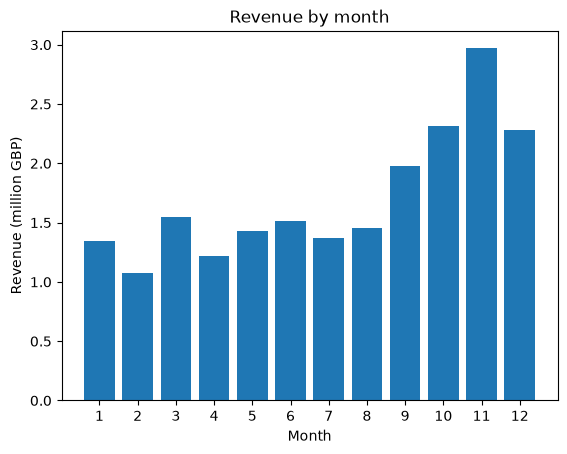

In [21]:
import matplotlib.pyplot as plt
df['month'] = df['InvoiceDate'].dt.month
monthly = df.groupby('month')['Revenue'].sum().round(0)
plt.bar(monthly.index, monthly.values / 1000000)
plt.title('Revenue by month')
plt.xlabel('Month')
plt.ylabel('Revenue (million GBP)')
plt.xticks(range(1, 13))
plt.savefig('../images/revenue_by_month.png', dpi=150, bbox_inches='tight')
plt.show()

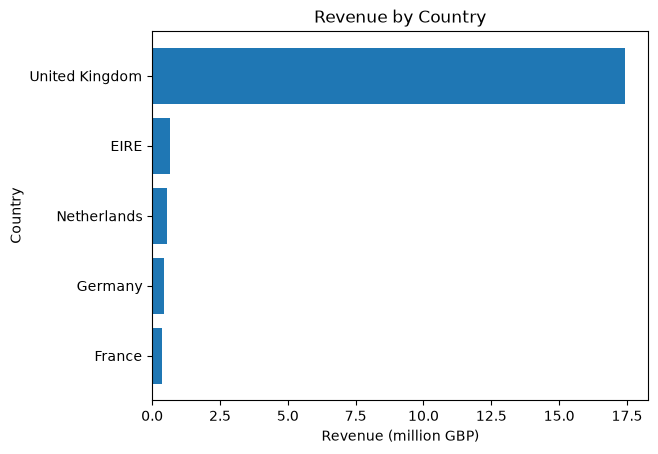

In [39]:
import matplotlib.pyplot as plt
countries = df.groupby('Country')['Revenue'].sum().round(0).sort_values(ascending=False).head(5)
plt.barh(countries.index, countries.values/1000000)
plt.title('Revenue by Country')
plt.xlabel('Revenue (million GBP)')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.savefig('../images/revenue_by_country.png', dpi=150, bbox_inches='tight')
plt.show()


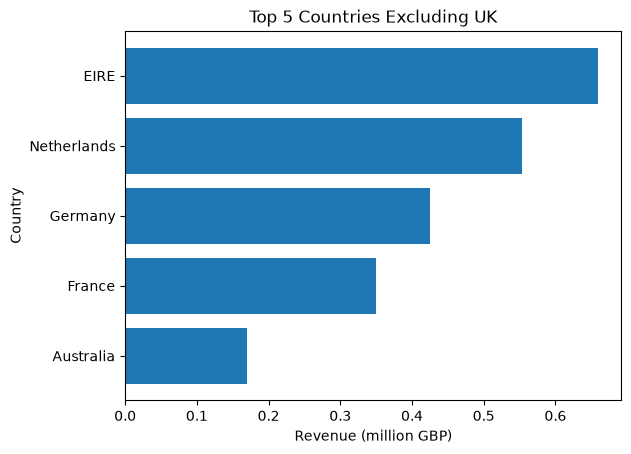

In [40]:
import matplotlib.pyplot as plt
df = df[df['Country'] != 'United Kingdom']
df_intl = df.groupby('Country')['Revenue'].sum().round(0).sort_values(ascending=False).head(5)
plt.barh(df_intl.index, df_intl.values/1000000)
plt.title('Top 5 Countries Excluding UK')
plt.xlabel('Revenue (million GBP)')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.savefig('../images/top_international_countries.png', dpi=150, bbox_inches='tight')
plt.show()